In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

<h3 align='center' style='color:orange'> Data Preparation</h3>

In [2]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\Machine-Learning\HomeWork1\car_fuel_efficiency_2026.csv")

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
df = df.fillna(0)

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [6]:
train_dicts = df_train.to_dict(orient='records')
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

### Question 1

In [7]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import export_text

In [8]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [9]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [10]:
print(export_text(dt, feature_names=dv.feature_names_))

|--- model_year <= 1995.50
|   |--- value: [28.47]
|--- model_year >  1995.50
|   |--- value: [31.10]



```Ans:'model_year'```

### Question 2

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=1)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print(rmse)

1.8067887258891118


```Ans:1.837```

### Question 3

In [12]:
for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(
        n_estimators=n,
        random_state=1,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    print(n, round(rmse, 3))

10 1.807
50 1.747
100 1.739
150 1.736


```Ans: 150```

### Question 4

In [13]:
scores = []

for d in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(
            n_estimators=n,
            max_depth=d,
            random_state=1,
            n_jobs=-1
        )

        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, y_pred))

        scores.append({
        'max_depth': d,
        'n_estimators': n,
        'rmse': rmse
        })

df_scores = pd.DataFrame(scores)
print(df_scores)

    max_depth  n_estimators      rmse
0          10            10  1.753946
1          10            50  1.722100
2          10           100  1.714565
3          10           150  1.711435
4          15            10  1.801045
5          15            50  1.745806
6          15           100  1.735800
7          15           150  1.731582
8          20            10  1.805624
9          20            50  1.749474
10         20           100  1.741730
11         20           150  1.736042
12         25            10  1.804883
13         25            50  1.746647
14         25           100  1.739498
15         25           150  1.736177


In [14]:
df_scores.groupby('max_depth').rmse.mean().round(3)

max_depth
10    1.726
15    1.754
20    1.758
25    1.757
Name: rmse, dtype: float64

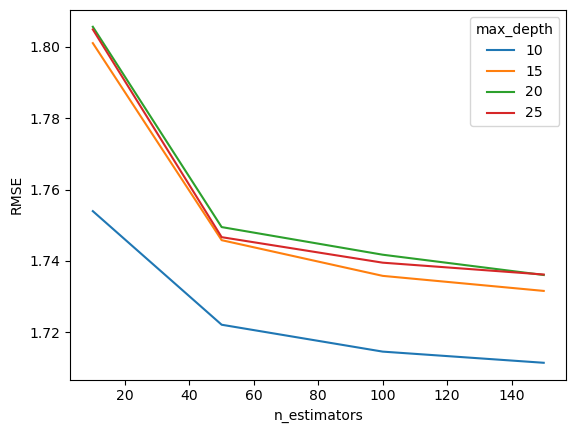

In [15]:
for d in [10, 15, 20, 25]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.rmse, label=d)

plt.xlabel('n_estimators')
plt.ylabel('RMSE')
plt.legend(title='max_depth')
plt.show()

```Ans:10    1.726```

### Question 5

In [16]:
rf = RandomForestRegressor(
    n_estimators=10,
    max_depth=20,
    random_state=1,
    n_jobs=-1
)

rf.fit(X_train, y_train)

importance = pd.DataFrame({
    'feature': dv.feature_names_,
    'importance': rf.feature_importances_
})

importance.sort_values(
    by='importance',
    ascending=False).head()

,feature,importance
9,model_year,0.305160
15,vehicle_weight,0.203259
6,fuel_type=Gasoline,0.144707
8,horsepower,0.076278
4,engine_displacement,0.063131


```Ans:vehicle_weight```

### Question 6

In [18]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)

# Common parameters
params = {
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'nthread': 8,
    'seed': 1,
    'verbosity': 0
}

# Compare eta values
for eta in [0.3, 0.1]:
    params['eta'] = eta

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=100,
        verbose_eval=False
    )

    y_pred = model.predict(dval)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    print(f'eta={eta}, RMSE={rmse:.6f}')

eta=0.3, RMSE=1.805297
eta=0.1, RMSE=1.707464


```Ans:0.1```